# Neural Radiance Fields (NeRF): A Minimal Implementation
In this notebook, we will implement a minimal version of Neural Radiance Fields (NeRF) proposed in:
> Mildenhall, B., Srinivasan, P. P., Tancik, M., Barron, J. T., Ramamoorthi, R., & Ng, R. (2020).
NeRF: Representing Scenes as Neural Radiance Fields for View Synthesis.
ECCV 2020.

In [1]:
# PyTorch NeRF Implementation
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm import tqdm
import imageio
from IPython.display import clear_output

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


# Data - Batching Rays
In this tutorial, we use a small synthetic dataset provided in the file "tiny_nerf_data.npz". This dataset is a simplified version of the data used in the original NeRF paper and contains everything needed to train a minimal model.
- images: [N, H, W, 3] Array with N images of shape 100x100 pixels with three color chanels (RGB).
- A single scalar representing the focal length of the camera in pixels.  This defines the intrinsic calibration matrix as
$$
\mathbf{K} =
\begin{bmatrix}
f & 0 & c_x \\
0 & f & c_y \\
0 & 0 & 1
\end{bmatrix}
$$
where $f$ is the focal length in pixels and $(c_x, c_y)$ is the principal point, here we consider $c_x = 0.5W$ and $c_y = 0.5H$.
- poses: [N, 4, 4] Array of Camera-to-World (C2W) transformation matrices. Each matrix $\mathbf{T}$ describes the camera's position and orientation in 3D space:

$$
\mathbf{T} =
\begin{bmatrix}
R^T & \mathbf{c} \\
\mathbf{0}^\top & 1
\end{bmatrix}
$$

where the top-left $3 \times 3$ block $R^T$ represents the rotation matrix, the top-right $3 \times 1$ vector $\mathbf{c}$ represents the position of the camera in the 3D space,  and the last row enforces homogeneous coordinates. $\mathbf{T}$ transforms a point from the camera's local frame into world coordinates. Its inverse is the world-to-camera (W2C) $\mathbf{T^{-1}} = [R | \mathbf{t}]$ transformation matrix, that defines the Pinhole Camera model as shown in the following figure:

![Title](pinhole_model.webp)

Using this model, a scene view can be formed by projecting 3D points into the image plane using a perspective transformation.


$$s \begin{bmatrix} 
u \\ 
v \\ 
1 
\end{bmatrix} = 
K
[ R \mid \mathbf{t} ]
\begin{bmatrix} 
X \\ 
Y \\ 
Z \\ 
1 
\end{bmatrix}$$


Let's read this dataset

In [2]:
data = np.load('tiny_nerf_data.npz')
images = torch.from_numpy(data['images']).float().to(device)
poses = torch.from_numpy(data['poses']).float().to(device)
focal = float(data['focal'])
H, W = images.shape[1:3]
K = torch.Tensor([[focal, 0, W/2.0], [0, focal, H/2.0], [0, 0, 1]]).float().to(device)
print(f"dataset: Images shape={images.shape}, Poses shape={poses.shape}, Intrinsics={K.shape}")

dataset: Images shape=torch.Size([106, 100, 100, 3]), Poses shape=torch.Size([106, 4, 4]), Intrinsics=torch.Size([3, 3])


Let's also split and visualise our the dataset

training split: torch.Size([100, 100, 100, 3]), training pose shape: torch.Size([100, 4, 4])
test split: torch.Size([6, 100, 100, 3]), test pose shape: torch.Size([6, 4, 4])


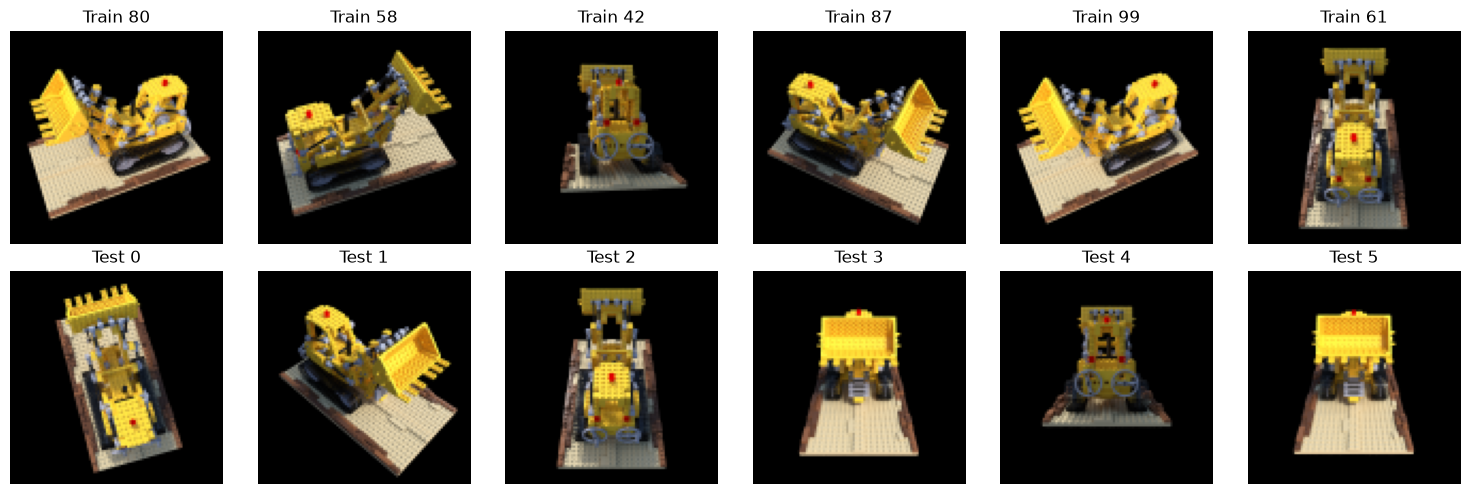

In [3]:
# spliting the dataset into training and test sets
test_images, test_poses = images[100:], poses[100:]
train_images, train_poses = images[:100], poses[:100]
print(f"training split: {train_images.shape}, training pose shape: {train_poses.shape}")
print(f"test split: {test_images.shape}, test pose shape: {test_poses.shape}")

# Create a figure with 2 rows and 6 columns
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

# Plot 6 training images in the first row
for i, sample_idx in enumerate(np.random.randint(0, train_images.shape[0], 6)):    
    axes[0, i].imshow(train_images[sample_idx].cpu().numpy())
    axes[0, i].set_title(f'Train {sample_idx}')
    axes[0, i].axis('off')

# Plot 6 test images in the second row
for i in range(6):
    axes[1, i].imshow(test_images[i].cpu().numpy())
    axes[1, i].set_title(f'Test {i}')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

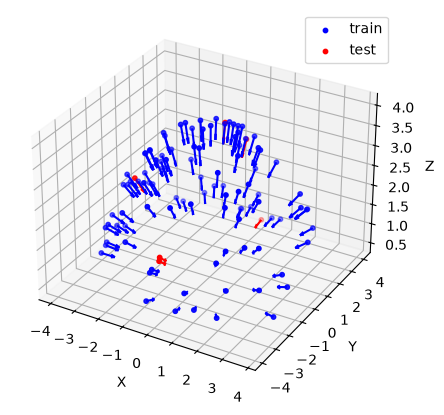

In [4]:
train_centers = train_poses[:, :3, 3].detach().cpu().numpy()
test_centers = test_poses[:, :3, 3].detach().cpu().numpy()

train_dirs = train_poses[:, :3, 2].detach().cpu().numpy()
test_dirs = test_poses[:, :3, 2].detach().cpu().numpy()

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(train_centers[:, 0], train_centers[:, 1], train_centers[:, 2], c="blue", s=10, label="train")
ax.scatter(test_centers[:, 0], test_centers[:, 1], test_centers[:, 2], c="red", s=10, label="test")

ax.quiver(
    train_centers[:, 0], train_centers[:, 1], train_centers[:, 2],
    -train_dirs[:, 0], -train_dirs[:, 1], -train_dirs[:, 2],
    length=0.5, color="blue", normalize=True
)
ax.quiver(
    test_centers[:, 0], test_centers[:, 1], test_centers[:, 2],
    -test_dirs[:, 0], -test_dirs[:, 1], -test_dirs[:, 2],
    length=0.5, color="red", normalize=True
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend()
plt.show()

NeRF learns a 3D scene by minimizing the error between rendered pixels and ground truth images. We treat our dataset $\mathcal{D}$ of $N$ posed images as a flattened "pool" of $M$ independent pixels, optimizing the network weights $\Theta$:

$$\min_{\Theta} \sum_{k=1}^{M} \| C_\theta(p_k) - I(p_k) \|^2$$

- $C_{\theta}(p)$: Predicted color for pixel $p$.
- $I(p)$: Ground truth RGB color.
    
Predicting color from 2D coordinates alone is ill-posed; we must bridge the gap to 3D by representing each pixel as a **Ray**. Given intrinsics $\mathbf{K}$ and camera-to-world pose $\mathbf{T}$, we define the ray $r(t) = \mathbf{o} + t \mathbf{d}$ as:

$$\begin{aligned} \mathbf{o} &= \mathbf{c} \\ \mathbf{d}_{\text{cam}} &= \begin{bmatrix} (u - c_x)/f_x & (v - c_y)/f_y & 1 \end{bmatrix}^\top \\ \mathbf{d} &= R \, \mathbf{d}_{\text{cam}} \\ \end{aligned}$$

Parameters:

- Origin ($\mathbf{o}$): Camera position in world space ($\mathbf{c}$).
- Direction ($\mathbf{d}$): Local camera vector rotated into world space.
-  $t$ represents the distance (or "time") traveled along the ray starting from the camera origin


To implement our objective function, we need a dataloader that provides batches of **ray origins**, **ray directions**, and **target colors** from our posed images. Let's start by computing all rays given an posed image...
    

In [5]:
def get_rays(K, c2w, H, W):
    """
    TODO: Get ray origin, direction to each image pixels based on camera pose
    """
    # 1. Create pixel grid, x first
    i, j = torch.meshgrid(
        torch.arange(W, dtype=torch.float32, device=c2w.device),
        torch.arange(H, dtype=torch.float32, device=c2w.device),
        indexing='xy'
    )
    

    # 2. Get directions in camera coordinates
    # We use the explicit K components: (u - cx)/fx, (v - cy)/fy
    # NeRF typically uses -1 for the z-axis (looking "into" the screen)
    dirs = torch.stack([
        (i - K[0, 2]) / K[0, 0],
        -(j - K[1, 2]) / K[1, 1],
        -torch.ones_like(i)
    ], dim=-1)
    
    # 3. Transform directions to world space
    # (H, W, 3) @ (3, 3) -> (H, W, 3)
    rays_d = dirs @ c2w[:3, :3].T
    
    # 4. Origin is the translation vector of the camera-to-world matrix
    rays_o = c2w[:3, -1].expand(rays_d.shape)
    
    return rays_o, rays_d

rays_o_i, rays_d_i = get_rays(K, train_poses[0], H, W)
rays_o_j, rays_d_j = get_rays(K, train_poses[10], H, W)
print(f"rays_o_i shape: {rays_o_i.shape}, rays_d_i shape: {rays_d_i.shape}")
print(f"rays_o_j shape: {rays_o_j.shape}, rays_d_j shape: {rays_d_j.shape}")

rays_o_i shape: torch.Size([100, 100, 3]), rays_d_i shape: torch.Size([100, 100, 3])
rays_o_j shape: torch.Size([100, 100, 3]), rays_d_j shape: torch.Size([100, 100, 3])


Now that, we know how to compute rays let's create our **NeRFDataset** and **Dataloader**...

In [6]:
class NeRFDataset(torch.utils.data.Dataset):
    def __init__(self, images, poses, intrinsic):
        """
        images: (N_images, H, W, 3)
        poses: (N_images, 4, 4)
        """
        # class attributes
        self.images, self.poses, self.intrinsic = images, poses, intrinsic        
        self.H, self.W = images.shape[1], images.shape[2]
        self.all_rays_o, self.all_rays_d, self.all_rays_rgbs = [], [], [] 

        # compute all rays
        for i in range(len(images)):
            rays_o, rays_d = get_rays(self.intrinsic, self.poses[i], self.H, self.W)
            self.all_rays_o.append(rays_o.reshape(-1, 3))            
            self.all_rays_d.append(rays_d.reshape(-1, 3))            
            self.all_rays_rgbs.append(images[i].reshape(-1, 3))

        # Concatenate all rays from all images
        self.all_rays_o = torch.cat(self.all_rays_o, dim=0)
        self.all_rays_d = torch.cat(self.all_rays_d, dim=0)
        self.all_rays_rgbs = torch.cat(self.all_rays_rgbs, dim=0)

    def __len__(self):
        return len(self.all_rays_o)

    def __getitem__(self, idx):
        return (self.all_rays_o[idx], self.all_rays_d[idx], self.all_rays_rgbs[idx])

train_dataloader = torch.utils.data.DataLoader(NeRFDataset(train_images, train_poses, K), batch_size=1024, shuffle=True)

Let's visualize some sampled rays...

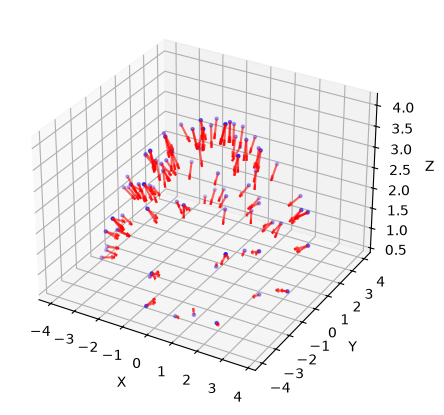

In [7]:
rays_o, rays_d, rays_rgb = next(iter(train_dataloader))
n = min(128, rays_o.shape[0])
rays_o = rays_o[:n].cpu().numpy()
rays_d = rays_d[:n].cpu().numpy()

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(rays_o[:, 0], rays_o[:, 1], rays_o[:, 2], s=5, c="blue", alpha=0.6)
ax.quiver(
    rays_o[:, 0], rays_o[:, 1], rays_o[:, 2],
    rays_d[:, 0], rays_d[:, 1], rays_d[:, 2],
    length=0.5, normalize=True, color="red", alpha=0.6
)
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

# Model - Neural Scene Representation

NeRF represents a scene as a continuous radiance field $F_{\mathbf{\theta}}$ that assigns:

<div style="display: flex; justify-content: center;">
    <img src="nerf_model.png" width="800">
</div>


- a **volume density** $\sigma$ (which encodes how likely a ray is to terminate at that location), and  
- an **emitted color** $\mathbf{c} = (r,g,b)$ (radiance),

to every 3D point $\mathbf{x} = (x,y,z)$ observed from a viewing direction $\mathbf{d} \in \mathbb{R}^3$.


### Positional Encoding

To allow the network to represent **high-frequency details**, each input is mapped to a higher-dimensional space using **positional encoding**:

$$
\gamma(\mathbf{x}) = \Big[
\mathbf{x}, \sin(2^0 \pi \mathbf{x}), \cos(2^0 \pi \mathbf{x}), \dots, \sin(2^{L-1} \pi \mathbf{x}), \cos(2^{L-1} \pi \mathbf{x})
\Big]
$$

$$
\gamma(\mathbf{d}) = \Big[
\mathbf{d}, \sin(2^0 \pi \mathbf{d}), \cos(2^0 \pi \mathbf{d}), \dots, \sin(2^{L-1} \pi \mathbf{d}), \cos(2^{L-1} \pi \mathbf{d})
\Big]
$$

- $L$ = number of frequency bands  
- $\gamma(\mathbf{x})$ and $\gamma(\mathbf{d})$ are used as inputs to the network instead of raw coordinates  
- This allows the MLP to model **high-frequency variations** in both geometry and appearance


Formally, the network becomes:

$$
F_{\mathbf{\theta}} : (\gamma(\mathbf{x}), \gamma(\mathbf{d})) \mapsto (\sigma, \mathbf{c})
$$

Here:

- $\mathbf{x} \in \mathbb{R}^3$ is a spatial location,
- $\mathbf{d} \in \mathbb{R}^3$ is a unit viewing direction,
- $\sigma \in \mathbb{R}_{\ge 0}$ represents volume density (geometry),
- $\mathbf{c} \in \mathbb{R}^3$ represents RGB color (appearance).

The density $\sigma(\mathbf{x})$ captures the scene geometry, while the color $\mathbf{c}(\mathbf{x}, \mathbf{d})$ captures appearance and view-dependent effects. 

To keep this tutorial lightweight and focused, we will use a simplified version of the original NeRF architecture.
- **No View-Dependence**: We consider only the 3D position $(x, y, z)$ of points, discarding the ray direction $(\theta, \phi)$. This means our model learns the "static" color of a point regardless of the angle from which it is viewed.
- **Simplified MLP**: Instead of the deep, 8-layer model with skip connections used in the original paper, we will implement a smaller Multi-Layer Perceptron (MLP). This reduces memory consumption and significantly speeds up training on smaller datasets.

Let’s define the network...

In [8]:

class PositionalEncoding(torch.nn.Module):
    """
    Positional encoding module
    """
    def __init__(self, L_embed=6):
        super(PositionalEncoding, self).__init__()
        # frequency bands used
        self.L_embed = L_embed
        self.bands = (2.0 ** torch.arange(L_embed, dtype=torch.float32).to(device)) * torch.pi
        self.bands = self.bands.view(1, L_embed, 1)  # shape (1, L_embed, 1)
    
    def forward(self, x):    
        # TODO: Implement positional encoding for input x (N, D) -> (N, D + 2*L_embed*D)    
        x_scaled = x.unsqueeze(-2) * self.bands  # shape (N, L, D)         
        sin_cos = torch.cat([torch.sin(x_scaled), torch.cos(x_scaled)], dim=-2) # shape (N, 2*L, D)
        sin_cos = sin_cos.flatten(start_dim=-2)  # (N, 2*L*D)
        encoded = torch.cat([x, sin_cos], dim=-1)  # (N, D + 2*L*D)
        return encoded


class NeRF(torch.nn.Module):
    """
    NeRF MLP model (only 3 layers for simplicity, no view-dependence)
    """
    def __init__(self, filter_size=128, L_embed=6):
        super(NeRF, self).__init__()
        self.positional_encoding = PositionalEncoding(L_embed)
        self.layer1 = torch.nn.Linear(3 + 3*2*L_embed, filter_size)
        self.layer2 = torch.nn.Linear(filter_size, filter_size)
        self.layer3 = torch.nn.Linear(filter_size, 4)
        self.relu = torch.nn.functional.relu
    
    def forward(self, x):
        # TODO: Implement the forward pass of NeRF MLP
        x = self.positional_encoding(x)
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.layer3(x)

        sigma = self.relu(x[..., [0]]) 
        rgb = torch.sigmoid(x[..., 1:])
        return torch.cat([sigma, rgb], dim=-1)
    
nerf = NeRF(filter_size=128, L_embed=6).to(device)
print(nerf)

NeRF(
  (positional_encoding): PositionalEncoding()
  (layer1): Linear(in_features=39, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=128, bias=True)
  (layer3): Linear(in_features=128, out_features=4, bias=True)
)


# Inference - Volume Rendering

At inference we need to use our neural radiance field to render the color of a ray (or pixel). NeRF simulates how light travels through the scene and reaches the camera.  This is implemented via **volume rendering**. The color of a ray $r(t)$ is computed as an integral of the radiance field along the ray:

$$
C_\theta(p) = C_\theta(r) = \int_{t_{\text{near}}}^{t_{\text{far}}} 
T(t)\, \sigma(r(t))\, \mathbf{c}(r(t), \mathbf{d}) \, dt,
$$

where:

- $\sigma(r(t))$ = volume density (geometry)  
- $\mathbf{c}(r(t), \mathbf{d})$ = RGB color (appearance)  
- $T(t)$ = transmittance, the probability that light travels from $t_{\text{near}}$ to $t$ without being absorbed.



In practice, we approximate it by sampling $N$ points $t_1, \dots, t_N$ along the ray. For each sample $i$, we define:

- $\mathbf{x}_i = r(t_i)$: The 3D position of the sample.
- $\sigma_i, \mathbf{c}_i$: The density and color predicted by the MLP at that position.
- $\delta_i = t_{i+1}-t_i$: The distance between adjacent samples.

We then convert these densities into opacities ($\alpha_i$) and calculate the accumulated transmittance 
($T_i$):$$\alpha_i = 1 - \exp(-\sigma_i \delta_i), \quad T_i = \prod_{j=1}^{i-1} (1-\alpha_j)$$

The final pixel color is the weighted sum of all colors along the ray:

$$C_\theta(r) \approx \sum_{i=1}^{N} T_i \alpha_i \mathbf{c}_i$$

Here, $T_i \alpha_i$ represents the visibility weight. It describes how much a specific 3D point contributes to the 2D pixel, accounting for both its own density and how much it is "blocked" by points in front of it. This formulation is fully differentiable, allowing us to backpropagate the loss from the 2D image back to the 3D density field. 

Let's code our volume rendering ...


In [9]:
def volume_rendering(sigma, rgb, t_vals):
    # TODO: Implement volume rendering to compute final pixel color from NeRF outputs
    
    # Calculate distance between samples (delta)
    # t_vals shape: [N_rays, N_samples]
    deltas = t_vals[..., 1:] - t_vals[..., :-1]
    
    
    # Append a large value (1e10) for the last interval
    last_dist = torch.full_like(deltas[..., :1], 1e10)
    deltas = torch.cat([deltas, last_dist], dim=-1)

    # alpha = 1.0 - exp(-sigma * delta)
    # sigma must be non-negative (usually ensured by ReLU in the MLP)
    alpha = 1.0 - torch.exp(-sigma * deltas)    
    
    # Transmittance T_i = product of (1 - alpha_j) for j < i
    # Use cumprod on (1-alpha) shifted by one position
    # prepend 1.0 because T_1 is always 1.0
    shifted_transmittance = torch.cat([torch.ones_like(alpha[..., :1]), 1.0 - alpha + 1e-10], dim=-1)
    T = torch.cumprod(shifted_transmittance, dim=-1)[..., :-1]

    # color blending
    weights = alpha * T
    rgb_map = torch.sum(weights[..., None] * rgb, dim=-2)
    
    return rgb_map, weights


Once we have the Volume Rendering equations, we can actually render rays—provided we know where to sample points in 3D space. The original NeRF model performs this using a hierarchical sampling approach: it uses a "coarse" network to predict the distribution of matter in space, and a "fine" network to learn the detailed geometry in occupied areas, avoiding empty space. 

However, in this tutorial, we opted for a simpler approach using a single network and stratified sampling. We divide the ray into $N$ bins and sample one point randomly from each. This ensures the network sees a continuous range of positions during training, rather than just fixed discrete points:
$$t_i \sim \mathcal{U} \left[ t_n + \frac{i-1}{N}(t_f-t_n), t_n + \frac{i}{N}(t_f-t_n) \right]$$
The MLP evaluates these points to produce densities and colors, which we then use to calculate the weights $w_i = T_i \alpha_i$. These weights represent the likelihood that a ray "hits" a surface at that specific depth, allowing us to render the final pixel color using volume rendering.

In [10]:

def render_rays(network, rays_o, rays_d, near, far, num_samples, rand=False):
    # TODO: Implement ray rendering by sampling points along rays, querying NeRF MLP, and volume rendering
    
    # 1. Generate t_vals for each ray: [N_rays, num_samples]
    z_vals = torch.linspace(near, far, num_samples, device=rays_o.device)
    z_vals = z_vals.expand(list(rays_o.shape[:-1])+[num_samples]) # N_rays, N_bin
        
    if rand:
        # 1.1 Add jitter
        bin_edges = torch.linspace(near, far, num_samples + 1, device=rays_o.device)
        lower = bin_edges[:-1]; widths = bin_edges[1:] - lower;
        z_vals = lower + torch.rand_like(z_vals) * widths

    # 2. Points in space: r(t) = o + td    
    pts = rays_o[..., None, :] + z_vals[..., :, None] * rays_d[..., None, :]

    # 3. network pass to compute density and color  
    raw_c = network(pts.view(-1,3))
    raw_c = raw_c.view(list(pts.shape[:-1]) + [4]) # Nrays, Nsamples, 4
    sigma, rgb = raw_c[..., 0], raw_c[..., 1:]

    # 4. Volume Rendering    
    rgb_map_c, weights_c = volume_rendering(sigma, rgb, z_vals)

    return rgb_map_c

# NeRF Training Procedure

We want the colors rendered by our network to match the ground-truth colors from our dataset. We achieve this by minimizing the Mean Squared Error (MSE) loss:
$$\mathcal{L} = \sum_{\mathbf{r} \in \mathcal{R}} \| C_\theta(\mathbf{r}) - I(\mathbf{r}) \|^2$$

- $C_\theta(\mathbf{r})$ is the color rendered by our MLP using the volume rendering equations.
- $I(\mathbf{r})$ is the true color of the pixel from the training image.

By backpropagating this loss, the MLP learns to assign high densities and correct colors to the specific 3D coordinates that when rendered produce correct visualization of the target object.

In practice, each training iteration follows these four steps::
1. **Ray Batching:** Our Dataloader randomly samples a batch of pixels from the training images and generates their world-space rays $\mathbf{r} = (\mathbf{o}, \mathbf{d})$.
2. **Ray Rendering:** We render the color of the batched rays using our network following the simplified sampling strategy and volume rendering equations. This returns the rendered color $C_\theta(\mathbf{r})$.
3. **Loss Calculation:** We compute the total loss $\mathcal{L}$ between the rendered outputs and the ground-truth colors $I(\mathbf{r})$.
4. **Backpropagation:** We update the weights $\theta$ of our network via gradient descent.

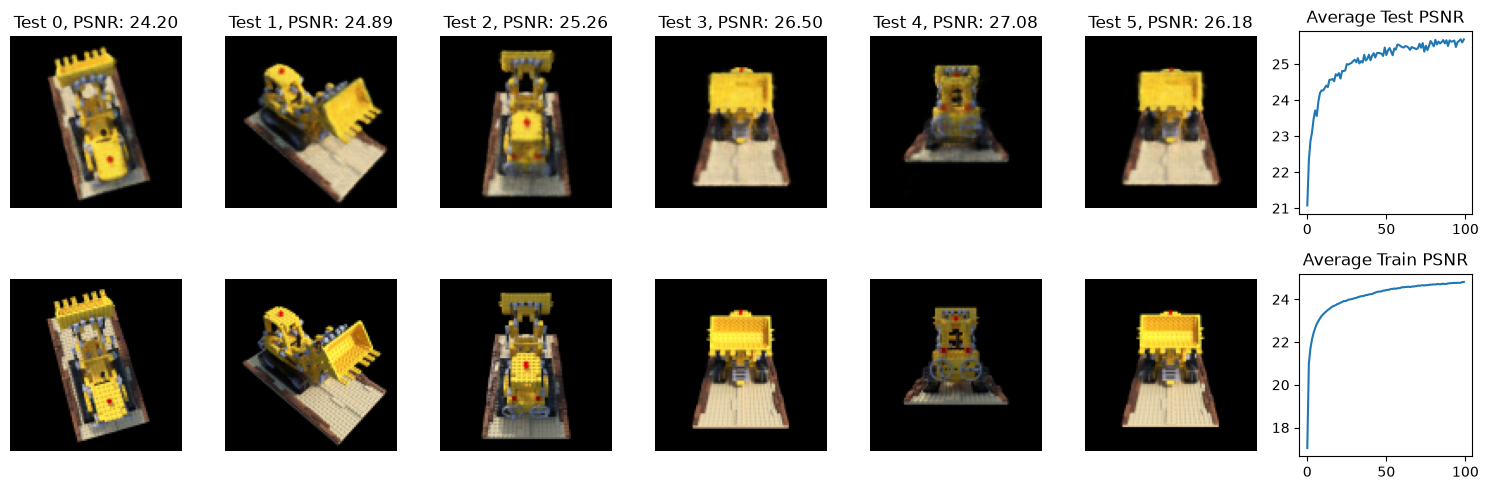

epoch 100/100 | train PSNR 24.81 | test PSNR 25.68 dB | 14.0s/epoch | ETA 0 min
Final average test PSNR (Tiny NeRF baseline): 25.68 dB


In [11]:
import pickle
import time
import os

# Reproducibility (same seed as the extended model for a fair comparison)
torch.manual_seed(1337)
np.random.seed(1337)

# Initialize model and optimizer
model = NeRF(filter_size=128, L_embed=6).to(device)
optimizer = optim.Adam(model.parameters(), lr=5e-4)

# training parameters
# NOTE: raised from the tutorial's 30 to 100 so the baseline is trained for the
# same number of epochs as the extended model (fair comparison for Task 3)
N_epochs = 100
# number of samples
N_samples = 64

train_psnrs, test_psnrs = [], []
start_epoch = 0

# ---- Resume from the last checkpoint if the kernel was culled mid-run ----
CKPT = 'ckpt_tiny.pth'
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optim'])
    train_psnrs, test_psnrs = ck['train_psnrs'], ck['test_psnrs']
    start_epoch = ck['epoch']
    print(f"Resumed from epoch {start_epoch} (test PSNR so far: {test_psnrs[-1]:.2f} dB)")

for epoch in range(start_epoch, N_epochs):

    # train
    avg_psnr, ray_count = 0.0, 0
    t0 = time.time()
    for rays_o, rays_d, rays_rgb in tqdm(train_dataloader,
                                         desc=f"epoch {epoch+1}/{N_epochs}",
                                         leave=False):
        optimizer.zero_grad()

        # 1. volume rendering of batches of rays
        rgb = render_rays(model, rays_o, rays_d, near=2.0, far=6.0, num_samples=N_samples, rand=True)

        # 2. loss computation
        loss = F.mse_loss(rgb, rays_rgb)

        # 3. Backward pass
        loss.backward()
        optimizer.step()

        # metric
        avg_psnr += (-10. * torch.log10(loss)).cpu().item()
        ray_count += 1

    # averge batch psnrs
    train_psnrs.append(avg_psnr / ray_count)
    epoch_time = time.time() - t0

    # test
    with torch.no_grad():
        clear_output(wait=True)
        fig, axes = plt.subplots(2, 7, figsize=(15, 5))
        avg_psnr = 0.0
        for test_idx in range(len(test_images)):
            # test image
            testimg, testpose = test_images[test_idx], test_poses[test_idx]

            # 1. Get rays for the test image
            rays_o, rays_d = get_rays(K, testpose, H, W)

            # 2. volume rendering of rays to get rgb values for each pixel
            rgb = render_rays(model, rays_o, rays_d, near=2., far=6., num_samples=N_samples, rand=False)

            # PSNR computation
            test_loss = F.mse_loss(rgb, testimg)
            psnr = (-10. * torch.log10(test_loss)).cpu().item()
            avg_psnr += psnr

            # plot rendered images and ground-truth images
            axes[0,test_idx].set_title(f"Test {test_idx}, PSNR: {psnr:.2f}");
            axes[0,test_idx].imshow(rgb.cpu().numpy()); axes[0, test_idx].axis('off');
            axes[1,test_idx].imshow(testimg.cpu().numpy()); axes[1, test_idx].axis('off');

        # plot test psnr
        test_psnrs.append(avg_psnr / len(test_images))
        axes[0,6].plot(test_psnrs, label='Test')
        axes[0,6].set_title('Average Test PSNR')
        axes[1,6].plot(train_psnrs, label='Train')
        axes[1,6].set_title('Average Train PSNR')
        plt.tight_layout()
        plt.show()

        print(f"epoch {epoch+1}/{N_epochs} | train PSNR {train_psnrs[-1]:.2f} | "
              f"test PSNR {test_psnrs[-1]:.2f} dB | {epoch_time:.1f}s/epoch | "
              f"ETA {(epoch_time*(N_epochs-epoch-1))/60:.0f} min")

        # Checkpoint every epoch so a culled kernel costs at most one epoch
        torch.save({'model': model.state_dict(),
                    'optim': optimizer.state_dict(),
                    'train_psnrs': train_psnrs,
                    'test_psnrs': test_psnrs,
                    'epoch': epoch + 1}, CKPT)

# Save final weights and curves for main_report.ipynb
torch.save(model.state_dict(), 'tiny.pth')
with open('psnrs_tiny.pkl', 'wb') as f:
    pickle.dump({'train': train_psnrs, 'test': test_psnrs}, f)
print(f"Final average test PSNR (Tiny NeRF baseline): {test_psnrs[-1]:.2f} dB")

## Interactive Visualization: Novel View Synthesis

After training, the NeRF has "learned" the scene's geometry and colors. To visualize this, we use an interactive tool that allows us to place a virtual camera anywhere on a sphere surrounding the object. We use **Spherical Coordinates** to define the camera's position relative to the center of the scene:

- **$\theta$ (Azimuth):** Rotates the camera horizontally around the object (left to right, $0^\circ$ to $360^\circ$).
- **$\phi$ (Elevation):** Moves the camera vertically (up and down, typically $-90^\circ$ to $90^\circ$).
- **Radius:** Adjusts the distance of the camera from the center (zoom in/out).

### How the tool works

1. **Coordinate Conversion:** The tool takes your slider values ($r, \theta, \phi$) and converts them into a standard $[4,4]$ Camera-to-World (c2w) matrix.
2. **Ray Generation:** Using the `get_rays` function we wrote earlier, it generates a new set of rays from this novel perspective.
3. **Inference:** These rays are passed through the NeRF MLP.
4. **Real-time Rendering:** The `render_rays` function applies volume rendering to produce the final image you see on the screen.


In [23]:
%matplotlib inline
from ipywidgets import interactive, widgets


trans_t = lambda t: torch.tensor([
    [1, 0, 0, 0],
    [0, 1, 0, 0],
    [0, 0, 1, t],
    [0, 0, 0, 1],
], dtype=torch.float32)

# Rotation about x-axis (phi)
rot_phi = lambda phi: torch.tensor([
    [1, 0, 0, 0],
    [0, torch.cos(phi), -torch.sin(phi), 0],
    [0, torch.sin(phi),  torch.cos(phi), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

# Rotation about y-axis (theta)
rot_theta = lambda th: torch.tensor([
    [torch.cos(th), 0, -torch.sin(th), 0],
    [0, 1, 0, 0],
    [torch.sin(th), 0,  torch.cos(th), 0],
    [0, 0, 0, 1],
], dtype=torch.float32)

def pose_spherical(theta, phi, radius):
    c2w = trans_t(radius)
    c2w = rot_phi(torch.tensor(phi / 180. * np.pi)) @ c2w
    c2w = rot_theta(torch.tensor(theta / 180. * np.pi)) @ c2w
    c2w = torch.tensor([
        [-1, 0, 0, 0],
        [ 0, 0, 1, 0],
        [ 0, 1, 0, 0],
        [ 0, 0, 0, 1],
    ], dtype=torch.float32) @ c2w
    return c2w.to(device)

def f(**kwargs):
    c2w = pose_spherical(**kwargs)
    rays_o, rays_d = get_rays(K, c2w[:3, :4], H, W)
    rgb = render_rays(model, rays_o, rays_d, near=2., far=6., num_samples=N_samples, rand=False)    
    img = rgb.detach().cpu().numpy()
    img = np.clip(img, 0, 1)

    
    plt.figure(2, figsize=(20, 6))
    plt.imshow(img)
    plt.show()

sldr = lambda v, mi, ma: widgets.FloatSlider(
    value=v,
    min=mi,
    max=ma,
    step=0.01,
)

names = [
    ['theta', [100., 0., 360.]],
    ['phi', [-30., -90., 0.]],
    ['radius', [4., 3., 5.]],
]

interactive_plot = interactive(f, **{s[0]: sldr(*s[1]) for s in names})
output = interactive_plot.children[-1]
output.layout.height = '350px'
interactive_plot


interactive(children=(FloatSlider(value=100.0, description='theta', max=360.0, step=0.01), FloatSlider(value=-…

# Taking NeRF Further

We have built the "Classic" NeRF, but the field has advanced significantly since its publication. For a deep dive into these modern advances, check out our Survey Paper.

> [Neural Radiance Fields for the Real World: A Survey](https://arxiv.org/abs/2501.13104)

### Other resources
- [Nerfstudio](https://docs.nerf.studio/): The go-to modular PyTorch framework for swapping models and real-time training visualization.

- [Instant-NGP](https://github.com/NVlabs/instant-ngp): NVIDIA’s hash-encoding breakthrough; achieves photorealism in seconds.

- 3D Gaussian Splatting: A fast alternative using 3D "blobs" instead of an MLP; currently the state-of-the-art for real-time rendering.

- [Awesome-NeRF](https://github.com/awesome-NeRF/awesome-NeRF): A curated repository of essential papers and datasets.
